# context

Re-evaluate the two normalization runs with progressively fewer disease protein edges. Same checkpoints, no retraining.

```
models  lsep / total + relation / n08
split   development / 136 diseases
mask    0 / 25 / 50 / 75 / 100%
seeds   146097 / 1 / 23
metric  recall@20 / ndcg@20
source  cda583e5a903
```

In [1]:
TRAIN_SHA = "cda583e5a90386f67f03e1208d14ab00f7405d6d"
DATA_SHA = "a29db6bb7019eefa4fd93d7b771f212cc88014a1"
RUNS = ("rgcn-lsep-total-n08", "rgcn-lsep-relation-n08")

FRACTIONS = (0.0, 0.25, 0.50, 0.75, 1.0)
MASK_SEEDS = (146097, 1, 23)

In [2]:
import csv
import hashlib
import json
import shutil
import subprocess
import sys
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch
from google.colab import files, userdata

REPO = Path("/content/exapt")
ROOT = Path("/content/exapt-context")
DATA = ROOT / "runs"
OUT = ROOT / "out"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("context: select a GPU runtime")

if not (REPO / ".git").is_dir():
    subprocess.run(["git", "clone", "--quiet", "https://github.com/aekn/exapt.git", str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "checkout", "--quiet", TRAIN_SHA], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", str(REPO)], check=True)

warnings.filterwarnings(
    "ignore", message=r"^Sparse CSR tensor support is in beta state\.",
    category=UserWarning, module=r"^exapt\.rgcn$",
)

from huggingface_hub import download_bucket_files
from exapt.benchmark import indication_partition, load_therapeutics
from exapt.evaluation import evaluate_ranking
from exapt.graph import load_graph, mask_disease_protein_context
from exapt.inference import load_selected, score_catalog
from exapt.primekg import fetch_primekg
from exapt.train import code_fingerprint

token = userdata.get("exapt_hf")
if not token:
    raise RuntimeError("context: missing Colab secret exapt_hf")

def read_json(path):
    return json.loads(path.read_text())

def write_csv(name, rows):
    with (OUT / name).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0])
        writer.writeheader()
        writer.writerows(rows)

print(f"source   {TRAIN_SHA[:12]} / {torch.cuda.get_device_name(0)}")

source   cda583e5a903 / NVIDIA L4


In [3]:
BUCKET = "exapt-lab/hangar"
run_data = {}
for run in RUNS:
    directory = DATA / run
    directory.mkdir(parents=True, exist_ok=True)
    download_bucket_files(
        BUCKET,
        files=[(f"runs/{run}/{name}", str(directory / name))
               for name in ("state.json", "benchmark.json", "development.json")],
        token=token, raise_on_missing_files=True,
    )
    state = read_json(directory / "state.json")
    selected = state["current"]["selected"]
    checkpoint = directory / "selected.pt"
    download_bucket_files(
        BUCKET, files=[(selected["path"], str(checkpoint))],
        token=token, raise_on_missing_files=True,
    )
    with checkpoint.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    if digest != selected["sha256"]:
        raise ValueError(f"context: checkpoint hash mismatch / {run}")

    run_data[run] = {
        "checkpoint": checkpoint,
        "selected_epoch": selected["epoch"],
        "state": state,
        "benchmark": read_json(directory / "benchmark.json"),
        "development": read_json(directory / "development.json"),
    }
    print(f"model    {run} / e{selected['epoch']:04d}")

if len({item["benchmark"]["sha256"] for item in run_data.values()}) != 1:
    raise ValueError("context: benchmark mismatch")

benchmark = run_data[RUNS[0]]["benchmark"]

model    rgcn-lsep-total-n08 / e0120


model    rgcn-lsep-relation-n08 / e0120


In [4]:
source = fetch_primekg(DATA_SHA, token=token)
facts = load_therapeutics(source)
diseases = tuple(benchmark["development"])
drugs = tuple(benchmark["drugs"])
positives = indication_partition(facts, frozenset(diseases))
graph = load_graph(
    source,
    withheld_diseases=frozenset(benchmark["development"] + benchmark["test"]),
    masked_pairs=frozenset(),
)

models, configs = {}, {}
for run in RUNS:
    item = run_data[run]
    model, metadata = load_selected(item["checkpoint"], graph, device="cuda")
    if (metadata["sha256"] != item["state"]["fingerprint"]
            or metadata["code_sha256"] != code_fingerprint()
            or metadata["benchmark_sha256"] != benchmark["sha256"]
            or metadata["dataset_revision"] != DATA_SHA
            or metadata["source_sha256"] != benchmark["source_sha256"]):
        raise ValueError(f"context: checkpoint identity mismatch / {run}")
    models[run] = model
    configs[run] = metadata["config"]

neighbors = {d: set() for d in diseases}
for relation, edges in zip(graph.relations, graph.edges, strict=True):
    if relation.name == "disease_protein" and relation.source_type == "disease":
        for disease, protein in zip(edges.source, edges.target, strict=True):
            if disease in neighbors:
                neighbors[disease].add(protein)

protein_counts = {d: len(proteins) for d, proteins in neighbors.items()}
protein_pairs = sum(protein_counts.values())
print(f"graph    {graph.edge_count:,} arcs / {protein_pairs:,} disease-protein pairs")
print(f"split    {len(diseases)} diseases / {len(drugs):,} drugs")

manifest.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

sources/primekg-2.1/kg.csv: reconstructing file:   0%|          |  0.00B /  982MB            

sources/primekg-2.1/kg.csv: downloading bytes:           |  0.00B            

graph    8,087,864 arcs / 4,567 disease-protein pairs
split    136 diseases / 7,957 drugs


In [5]:
stress, per_disease, paired = [], [], []

for fraction in FRACTIONS:
    seeds = MASK_SEEDS if 0 < fraction < 1 else MASK_SEEDS[:1]
    for seed in seeds:
        masked = mask_disease_protein_context(
            graph, frozenset(diseases), fraction=fraction, seed=seed,
        )
        removed_pairs = sum(int(count * fraction) for count in protein_counts.values())
        removed_arcs = graph.edge_count - masked.edge_count
        actual = removed_pairs / protein_pairs
        outcomes = {}

        for run in RUNS:
            config = configs[run]
            scores = score_catalog(
                models[run], masked,
                diseases=diseases, drugs=drugs,
                encoder=config["encoder"], normalization=config["normalization"],
                layout=config["layout"], device="cuda",
            )
            result = evaluate_ranking(
                scores, diseases=diseases, drugs=drugs, positives=positives, k=20,
            )
            if fraction == 0:
                expected = run_data[run]["development"]
                if (abs(result.recall - expected["recall"]) > 1e-6
                        or abs(result.ndcg - expected["ndcg"]) > 1e-6):
                    raise ValueError(
                        f"context: baseline mismatch / {run} / "
                        f"recall {result.recall:.6f} != {expected['recall']:.6f} / "
                        f"ndcg {result.ndcg:.6f} != {expected['ndcg']:.6f}"
                    )

            outcomes[run] = result
            stress.append({
                "run": run, "fraction": fraction, "seed": seed,
                "removed_pairs": removed_pairs, "removed_arcs": removed_arcs,
                "actual_fraction": actual, "recall20": result.recall,
                "ndcg20": result.ndcg, "n": len(diseases),
            })
            per_disease.extend({
                "run": run, "fraction": fraction, "seed": seed,
                "disease": row.disease, "protein_neighbors": protein_counts[row.disease],
                "recall20": row.recall, "ndcg20": row.ndcg,
            } for row in result.per_disease)

        total, relation = (outcomes[run] for run in RUNS)
        paired.append({
            "fraction": fraction, "seed": seed,
            "actual_fraction": actual, "removed_pairs": removed_pairs,
            "recall_difference": relation.recall - total.recall,
            "ndcg_difference": relation.ndcg - total.ndcg,
        })
        print(f"mask     {actual:6.1%} / seed {seed} / "
              f"R@20 {total.recall:.4f} {relation.recall:.4f} / "
              f"delta {relation.recall - total.recall:+.4f}")

write_csv("stress.csv", stress)
write_csv("stress_diseases.csv", per_disease)
write_csv("paired.csv", paired)
(OUT / "protocol.json").write_text(json.dumps({
    "training_sha": TRAIN_SHA,
    "dataset_revision": DATA_SHA,
    "benchmark_sha256": benchmark["sha256"],
    "runs": {run: run_data[run]["selected_epoch"] for run in RUNS},
    "fractions": FRACTIONS,
    "mask_seeds": MASK_SEEDS,
    "development_diseases": len(diseases),
    "catalog_drugs": len(drugs),
    "visible_arcs": graph.edge_count,
    "protein_pairs": protein_pairs,
    "device": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
}, indent=2) + "\n")

/usr/local/lib/python3.13/dist-packages/exapt/rgcn.py:59: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  matrix = torch.sparse_coo_tensor(


mask       0.0% / seed 146097 / R@20 0.2948 0.4390 / delta +0.1442
mask      24.3% / seed 146097 / R@20 0.2915 0.4397 / delta +0.1482
mask      24.3% / seed 1 / R@20 0.2954 0.4380 / delta +0.1426
mask      24.3% / seed 23 / R@20 0.2952 0.4251 / delta +0.1299
mask      49.5% / seed 146097 / R@20 0.2739 0.4272 / delta +0.1532
mask      49.5% / seed 1 / R@20 0.2682 0.4293 / delta +0.1611
mask      49.5% / seed 23 / R@20 0.2775 0.4254 / delta +0.1479
mask      74.2% / seed 146097 / R@20 0.2538 0.4143 / delta +0.1604
mask      74.2% / seed 1 / R@20 0.2640 0.4041 / delta +0.1401
mask      74.2% / seed 23 / R@20 0.2674 0.4089 / delta +0.1415
mask     100.0% / seed 146097 / R@20 0.1606 0.2191 / delta +0.0585


581

In [6]:
from matplotlib import font_manager

FONT_DIR = ROOT / "fonts"
FONT_DIR.mkdir(exist_ok=True)
FONTS = {
    "SourceSans3-Medium.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Medium.ttf",
    "SourceSans3-Semibold.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Semibold.ttf",
    "UbuntuMono-Regular.ttf": "https://raw.githubusercontent.com/google/fonts/main/ufl/ubuntumono/UbuntuMono-Regular.ttf",
}
for filename, url in FONTS.items():
    path = FONT_DIR / filename
    if not path.exists():
        urlretrieve(url, path)
    font_manager.fontManager.addfont(path)

SANS = font_manager.FontProperties(fname=FONT_DIR / "SourceSans3-Medium.ttf").get_name()
MONO = font_manager.FontProperties(fname=FONT_DIR / "UbuntuMono-Regular.ttf").get_name()

P = {
    "panel": "#202020", "grid": "#404040",
    "fg": "#e4e4ef", "muted": "#a0a0a0",
    "cyan": "#89a6a5", "orange": "#b69971",
}

mpl.rcParams.update({
    "font.family": SANS, "font.weight": "medium", "font.size": 18,
    "axes.labelsize": 20, "axes.labelweight": "semibold", "axes.labelpad": 20,
    "xtick.labelsize": 17, "ytick.labelsize": 17, "legend.fontsize": 17,
    "figure.facecolor": P["panel"], "axes.facecolor": P["panel"],
    "savefig.facecolor": P["panel"], "text.color": P["fg"],
    "axes.labelcolor": P["fg"], "axes.edgecolor": P["grid"],
    "xtick.color": P["muted"], "ytick.color": P["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "grid.color": P["grid"], "grid.alpha": 0.65,
    "svg.fonttype": "path", "pdf.fonttype": 42,
})


def save(fig, name):
    for ext in ("svg", "pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300,
                    bbox_inches="tight", pad_inches=0.25)
    plt.show()
    plt.close(fig)

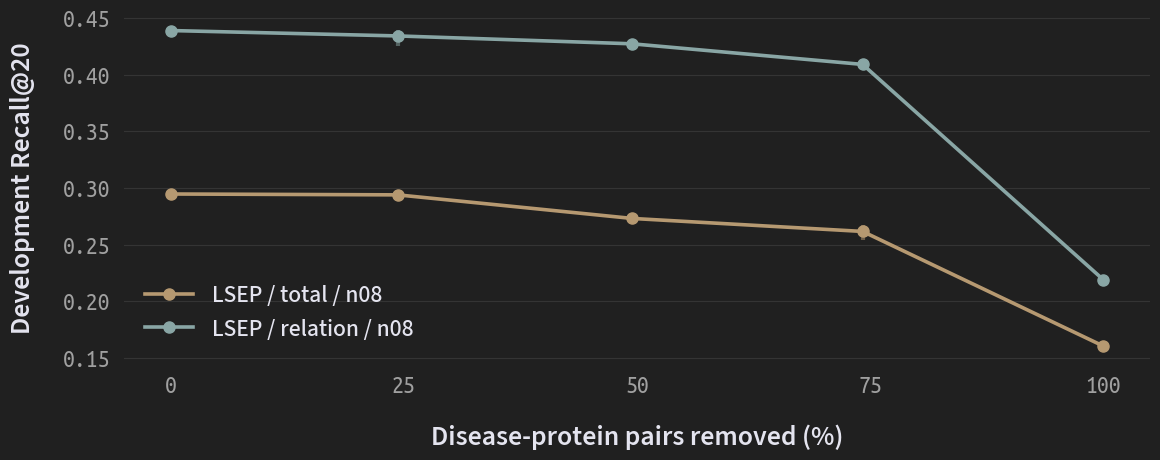

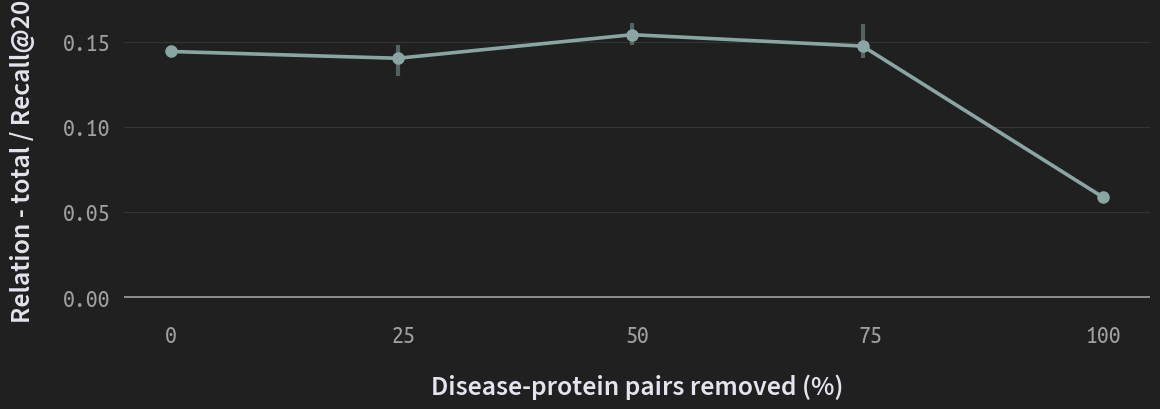

In [7]:
fractions = sorted({row["fraction"] for row in stress})
fig, ax = plt.subplots(figsize=(12, 5.0))
for run, color, label in (
    (RUNS[0], P["orange"], "LSEP / total / n08"),
    (RUNS[1], P["cyan"], "LSEP / relation / n08"),
):
    groups = [[r for r in stress if r["run"] == run and r["fraction"] == fraction]
              for fraction in fractions]
    x = [100 * values[0]["actual_fraction"] for values in groups]
    y = [np.mean([row["recall20"] for row in values]) for values in groups]
    ax.plot(x, y, "o-", linewidth=2.6, markersize=8, color=color, label=label)
    for value, records in zip(x, groups, strict=True):
        ys = [record["recall20"] for record in records]
        if len(ys) > 1:
            ax.vlines(value, min(ys), max(ys), color=color, linewidth=3, alpha=0.5)

ax.set(xlabel="Disease-protein pairs removed (%)", ylabel="Development Recall@20")
ax.set_xticks(np.arange(0, 101, 25))
ax.legend(frameon=False, labelcolor=P["fg"])
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "context")

fig, ax = plt.subplots(figsize=(12, 4.5))
groups = [[row for row in paired if row["fraction"] == fraction] for fraction in fractions]
x = [100 * rows[0]["actual_fraction"] for rows in groups]
y = [np.mean([row["recall_difference"] for row in rows]) for rows in groups]
ax.plot(x, y, "o-", linewidth=2.6, markersize=8, color=P["cyan"])
for value, records in zip(x, groups, strict=True):
    ys = [record["recall_difference"] for record in records]
    if len(ys) > 1:
        ax.vlines(value, min(ys), max(ys), color=P["cyan"], linewidth=3, alpha=0.5)
ax.axhline(0, color=P["muted"], linewidth=1.2)
ax.set(xlabel="Disease-protein pairs removed (%)", ylabel="Relation - total / Recall@20")
ax.set_xticks(np.arange(0, 101, 25))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "difference")

In [8]:
archive = shutil.make_archive(str(ROOT / "exapt-context"), "zip", OUT)
print(f"export   {archive}")
files.download(archive)

export   /content/exapt-context/exapt-context.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>